# Stroke Risk Prediction — Data Cleanup & Preprocessing

**Course:** Machine Learning — Mid-Term Project (Modules 4 & 5)
**Target variable:** `Stroke` (binary: 0 = no stroke, 1 = stroke)
**Dataset:** Patient health records (≥ 2,000 rows), source documented in Section 1

This notebook takes the raw dataset through a complete, reproducible preprocessing pipeline and shows **before / after** views at every step. **All changes are made in Python code — the data is never edited manually.**

| # | Section | Requirement covered |
|---|---------|---------------------|
| 1 | Setup & data loading | Dataset source, ≥ 2,000 rows |
| 2 | Train / test split | 70 / 30 stratified, done in Python; test set held out |
| 3 | Initial inspection (train) | Sample data, types, missing values |
| 4 | Exploratory analysis (train only) | Matplotlib distributions |
| 5 | Missing & invalid values | Filling NaN / Null values |
| 6 | Encoding | Categorical → numeric, one-hot encoding |
| 7 | Feature engineering | New clinical features |
| 8 | Normalization & scaling | Distribution shape and range |
| 9 | Class balancing | SMOTE-NC on training data only |
| 10 | Baseline models | Evidence that preprocessing is useful |
| 11 | Using the dataset to solve an ML problem | Discussion |
| 12 | Export | Processed files |

> **Design principle:** the split happens *first*, and EDA uses the training set only. Every imputer, transformer, scaler and resampler is **fit on the training set only** and then applied to the test set, so no information leaks from test to train.

## 1. Setup & Data Loading

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, precision_score,
                             recall_score, f1_score)

try:
    from imblearn.over_sampling import SMOTENC
except ImportError:                      # e.g. fresh Colab runtime
    %pip install -q imbalanced-learn
    from imblearn.over_sampling import SMOTENC

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*vert.*")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

# ---- Project configuration -------------------------------------------------
RANDOM_STATE = 42
TARGET       = "Stroke"
ID_COLUMNS   = ["Patient_ID"]            # identifiers carry no medical signal
TEST_SIZE    = 0.30                      # 70 / 30 split
BMI_MIN      = 15                        # BMI below this is physiologically implausible

DATASET_URL = ("https://docs.google.com/spreadsheets/d/"
               "1wQTS2-bZKC2n17To2Smp1NAFMFeBEjh_rklu0wi7mu0/edit#gid=1445603174")
SHEET_ID, GID = "1wQTS2-bZKC2n17To2Smp1NAFMFeBEjh_rklu0wi7mu0", "1445603174"
CSV_EXPORT_URL = f"https://docs.google.com/spreadsheets/d/{SHEET_ID}/export?format=csv&gid={GID}"
KAGGLE_URL = "https://www.kaggle.com/datasets/rafi003/healthcare-disease-prediction-dataset?resource=download>"

COLORS = {"neg": "#5B7C99", "pos": "#C0392B", "after": "#2E8B7A", "before": "#E39B3B"}

In [2]:
def show_sample(df, title, n=5, cols=None):
    """Print a labelled sample so every processing step is visible."""
    print(f"\n--- {title} (first {n} rows, shape {df.shape}) ---")
    display(df[cols].head(n) if cols else df.head(n))

def load_data():
    """Prefer a local CSV; otherwise read straight from the shared Google Sheet."""
    for name in ("stroke_dataset.csv", "dataset.csv", "data.csv"):
        if Path(name).exists():
            return pd.read_csv(name), f"local file: {name}"
    return pd.read_csv(CSV_EXPORT_URL), "Google Sheets export"

df_raw, source = load_data()
Path("dataset_url.txt").write_text(f"Kaggle source: {KAGGLE_URL}\nWorking copy: {DATASET_URL}\n")
print(f"Loaded from {source}")
print(f"Rows: {len(df_raw):,}   Columns: {df_raw.shape[1]}")
assert len(df_raw) >= 2000, "Assignment requires at least 2,000 rows"
print("✓ Row-count requirement (≥ 2,000) satisfied")

df = df_raw.drop(columns=[c for c in ID_COLUMNS if c in df_raw.columns])
print(f"✓ Dropped identifier column(s): {[c for c in ID_COLUMNS if c in df_raw.columns]}")

Loaded from Google Sheets export
Rows: 2,000   Columns: 15
✓ Row-count requirement (≥ 2,000) satisfied
✓ Dropped identifier column(s): ['Patient_ID']


## 2. Train / Test Split (70 / 30, stratified)

The split is done **in Python, immediately after loading** — never manually or in Excel. From this point on, the **test set is not touched**: inspection, EDA and every learned preprocessing step (imputation values, scaler parameters, resampling) use the **training set only**. The split is stratified on `Stroke` so both sets keep the same class ratio.

`Heart_Disease` and `Diabetes` stay in the feature set as medical risk factors; `Stroke` is the only target.

In [3]:
NUMERIC = ["Age", "BMI", "Blood_Pressure_Systolic", "Blood_Pressure_Diastolic",
           "Cholesterol", "Glucose_Level"]
BINARY  = [c for c in df.columns if c not in NUMERIC + ["Gender", TARGET]]

X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape[0]:,} rows ({len(X_train)/len(df):.0%})  |  "
      f"Test: {X_test.shape[0]:,} rows ({len(X_test)/len(df):.0%}) — held out, untouched")
print(f"Stroke rate  train: {y_train.mean():.2%}   test: {y_test.mean():.2%}")

# Training data loaded into memory for inspection & EDA (test set is NOT used below)
train_df = X_train.assign(**{TARGET: y_train})

# Keep untouched copies for before/after comparisons later
X_train_raw, X_test_raw = X_train.copy(), X_test.copy()

Train: 1,400 rows (70%)  |  Test: 600 rows (30%) — held out, untouched
Stroke rate  train: 5.07%   test: 5.17%


## 3. Initial Inspection (training set)

Before changing anything we record what the **training data** looks like: types, a sample, summary statistics, missing values and duplicates.

In [4]:
show_sample(train_df, "RAW DATA", n=5)

print("\nData types & non-null counts")
train_df.info()

print("\nSummary statistics (numeric)")
display(train_df.describe().T.round(2))

missing = train_df.isna().sum()
print("\nMissing values per column:")
print(missing[missing > 0] if missing.any() else "None — no NaN / null values in the raw file.")
print(f"\nDuplicate rows: {train_df.duplicated().sum()}")


--- RAW DATA (first 5 rows, shape (1400, 14)) ---


,Age,Gender,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol,Glucose_Level,Smoking,Alcohol_Intake,Physical_Activity,Family_History,Heart_Disease,Diabetes,Stroke
725,22,Female,22.4,144,107,211,85,1,1,0,1,0,0,0
1651,30,Male,36.7,167,113,211,117,1,0,1,0,0,0,0
1193,26,Male,25.9,114,108,275,160,1,1,0,1,0,0,0
994,39,Male,36.5,115,85,260,154,1,1,1,1,0,1,0
980,22,Female,28.1,155,81,162,124,0,1,1,1,0,0,0



Data types & non-null counts
<class 'pandas.core.frame.DataFrame'>
Index: 1400 entries, 725 to 419
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       1400 non-null   int64  
 1   Gender                    1400 non-null   object 
 2   BMI                       1400 non-null   float64
 3   Blood_Pressure_Systolic   1400 non-null   int64  
 4   Blood_Pressure_Diastolic  1400 non-null   int64  
 5   Cholesterol               1400 non-null   int64  
 6   Glucose_Level             1400 non-null   int64  
 7   Smoking                   1400 non-null   int64  
 8   Alcohol_Intake            1400 non-null   int64  
 9   Physical_Activity         1400 non-null   int64  
 10  Family_History            1400 non-null   int64  
 11  Heart_Disease             1400 non-null   int64  
 12  Diabetes                  1400 non-null   int64  
 13  Stroke                    1400 non-nu

,count,mean,std,min,25%,50%,75%,max
Age,1400.0,50.09,19.50,18.0,33.00,50.0,67.00,84.0
BMI,1400.0,26.98,4.92,9.6,23.60,26.8,30.42,42.3
Blood_Pressure_Systolic,1400.0,134.66,26.11,90.0,112.00,135.0,158.00,179.0
Blood_Pressure_Diastolic,1400.0,88.98,17.13,60.0,74.00,89.0,104.00,119.0
Cholesterol,1400.0,224.21,43.57,150.0,186.75,224.5,263.00,299.0
Glucose_Level,1400.0,132.89,36.82,70.0,100.00,133.0,164.00,199.0
Smoking,1400.0,0.50,0.50,0.0,0.00,1.0,1.00,1.0
Alcohol_Intake,1400.0,0.50,0.50,0.0,0.00,1.0,1.00,1.0
Physical_Activity,1400.0,0.50,0.50,0.0,0.00,1.0,1.00,1.0
Family_History,1400.0,0.50,0.50,0.0,0.00,1.0,1.00,1.0



Missing values per column:
None — no NaN / null values in the raw file.

Duplicate rows: 0


## 4. Exploratory Analysis (training data only)

These plots describe the **training set as received** — the test set is not used. They guide the cleanup decisions in later sections: class imbalance, skewness, implausible values and feature relationships.

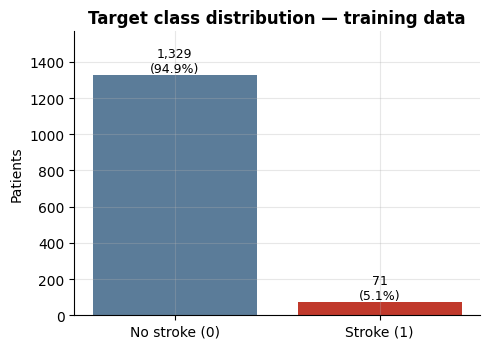

Imbalance ratio (negative : positive) = 18.7 : 1


In [5]:
# 3.1 Target balance --------------------------------------------------------
counts = train_df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3.6))
bars = ax.bar(["No stroke (0)", "Stroke (1)"], counts.values,
              color=[COLORS["neg"], COLORS["pos"]])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v/len(train_df):.1%})",
            ha="center", va="bottom", fontsize=9)
ax.set_title("Target class distribution — training data", fontweight="bold")
ax.set_ylabel("Patients"); ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout(); plt.show()
print(f"Imbalance ratio (negative : positive) = {counts[0] / counts[1]:.1f} : 1")

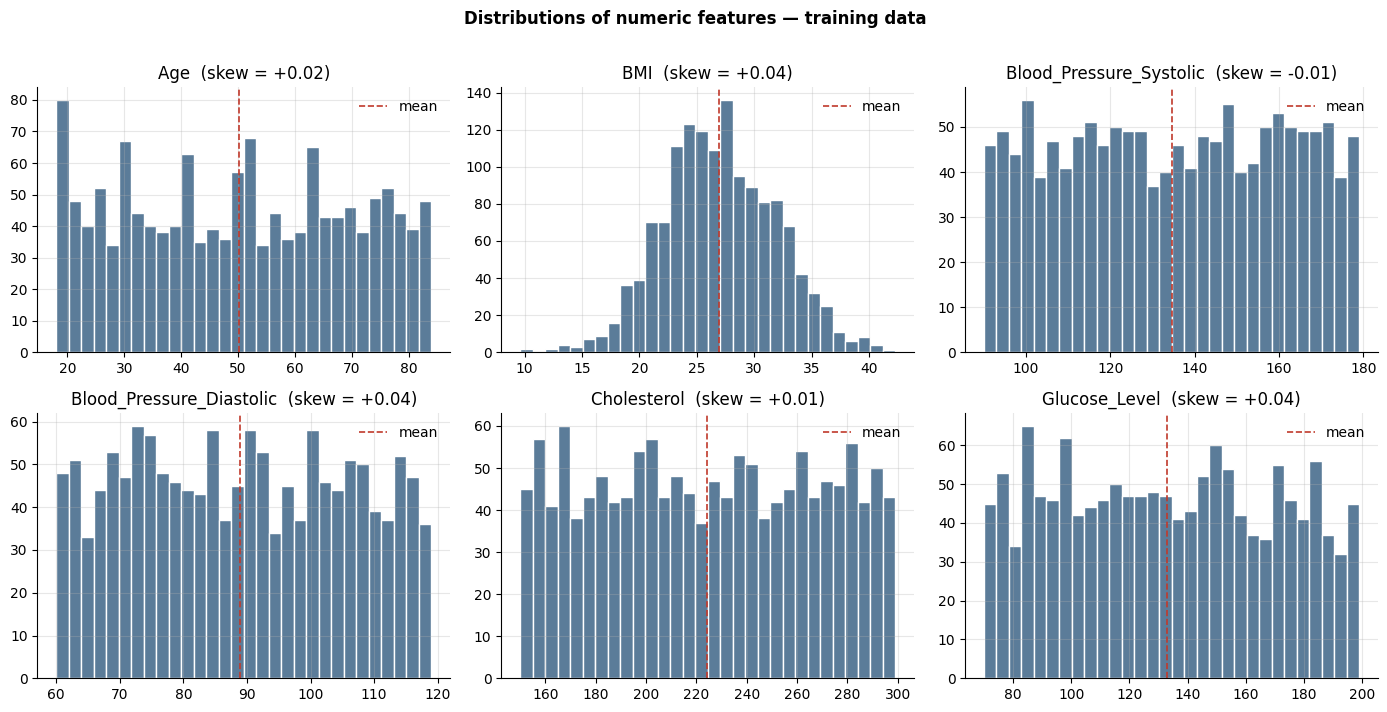

In [6]:
# 3.2 Numeric distributions + skewness -------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), NUMERIC):
    ax.hist(train_df[col], bins=30, color=COLORS["neg"], edgecolor="white")
    ax.axvline(train_df[col].mean(), color=COLORS["pos"], ls="--", lw=1.2, label="mean")
    ax.set_title(f"{col}  (skew = {train_df[col].skew():+.2f})")
    ax.legend(frameon=False)
fig.suptitle("Distributions of numeric features — training data", fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

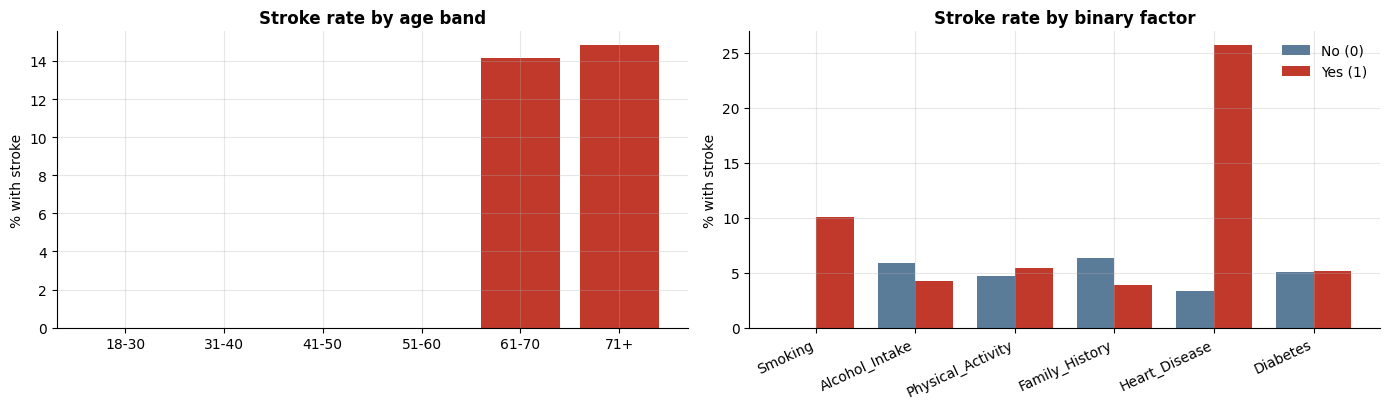

In [7]:
# 3.3 Stroke rate by age band and by lifestyle factor -----------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

bands = pd.cut(train_df["Age"], [17, 30, 40, 50, 60, 70, 120],
               labels=["18-30", "31-40", "41-50", "51-60", "61-70", "71+"])
rate = train_df.groupby(bands, observed=True)[TARGET].mean() * 100
axes[0].bar(rate.index.astype(str), rate.values, color=COLORS["pos"])
axes[0].set_title("Stroke rate by age band", fontweight="bold")
axes[0].set_ylabel("% with stroke")

life = [c for c in BINARY if c != TARGET]
r = {c: (train_df.groupby(c)[TARGET].mean() * 100).reindex([0, 1]) for c in life}
x = np.arange(len(life)); w = 0.38
axes[1].bar(x - w/2, [r[c][0] for c in life], w, label="No (0)", color=COLORS["neg"])
axes[1].bar(x + w/2, [r[c][1] for c in life], w, label="Yes (1)", color=COLORS["pos"])
axes[1].set_xticks(x); axes[1].set_xticklabels(life, rotation=25, ha="right")
axes[1].set_title("Stroke rate by binary factor", fontweight="bold")
axes[1].set_ylabel("% with stroke"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

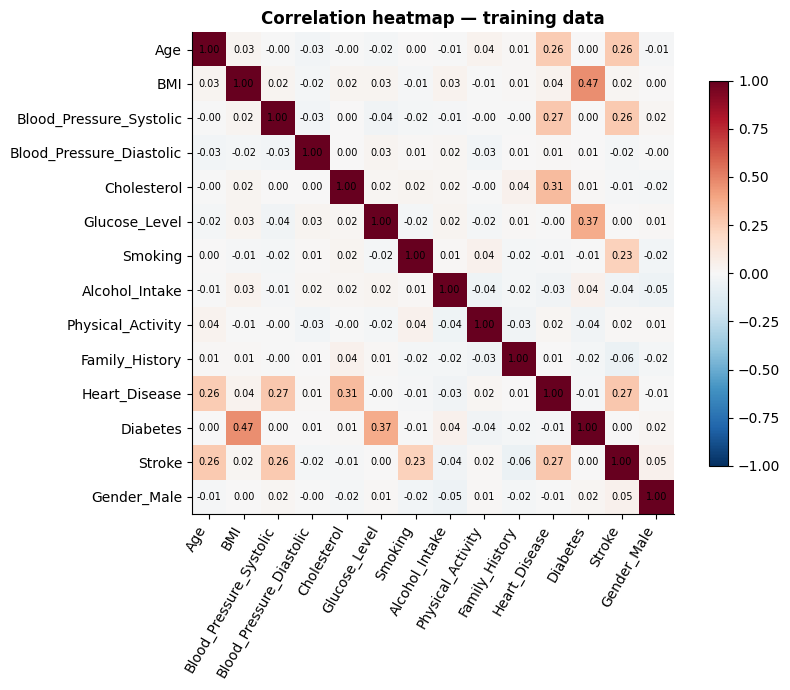

Strongest correlations with Stroke:
Heart_Disease              0.273
Age                        0.262
Blood_Pressure_Systolic    0.258
Smoking                    0.230
Family_History             0.056


In [8]:
# 3.4 Correlation heatmap ---------------------------------------------------
num_df = train_df.assign(Gender_Male=(train_df["Gender"] == "Male").astype(int)).select_dtypes("number")
corr = num_df.corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation heatmap — training data", fontweight="bold")
plt.tight_layout(); plt.show()

print("Strongest correlations with Stroke:")
print(corr[TARGET].drop(TARGET).abs().sort_values(ascending=False).head(5).round(3).to_string())

Implausible BMI (< 15):                10 rows
Diastolic ≥ systolic (suspicious):       124 rows (8.9%)


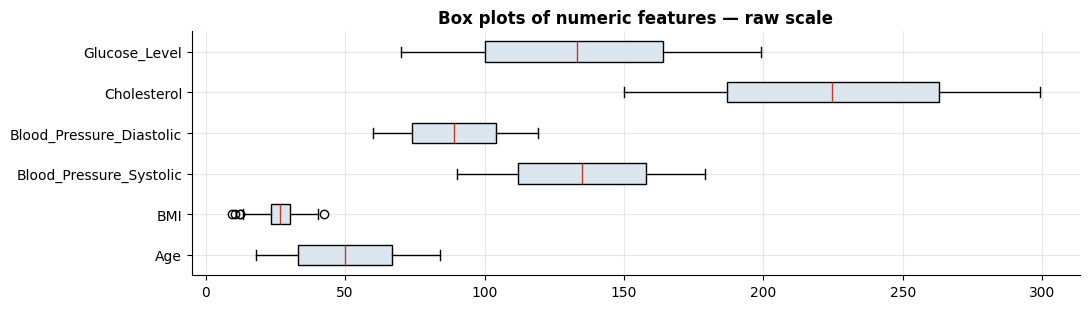

In [9]:
# 3.5 Data-quality checks that drive Section 5 & 7 --------------------------
n_bmi   = (train_df["BMI"] < BMI_MIN).sum()
n_bp    = (train_df["Blood_Pressure_Diastolic"] >= train_df["Blood_Pressure_Systolic"]).sum()
print(f"Implausible BMI (< {BMI_MIN}):                {n_bmi} rows")
print(f"Diastolic ≥ systolic (suspicious):       {n_bp} rows ({n_bp/len(train_df):.1%})")

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.boxplot([train_df[c] for c in NUMERIC], vert=False, patch_artist=True,
           boxprops=dict(facecolor="#DCE6EE"), medianprops=dict(color=COLORS["pos"]))
ax.set_yticklabels(NUMERIC)
ax.set_title("Box plots of numeric features — raw scale", fontweight="bold")
plt.tight_layout(); plt.show()

## 5. Missing & Invalid Values

The raw file has no `NaN`s, but it contains **physiologically impossible BMI values** (below 15). These are data-entry errors, not real patients, so they are first converted to `NaN` and then filled with the **training-set median** (robust to outliers). The same imputer — fitted on train only — is applied to the test set.

A `most_frequent` imputer is also configured for `Gender`, so the pipeline is safe if future data contains blanks.

NaN count after flagging invalid BMI values
  train: 10   test: 5

--- BEFORE — rows with implausible BMI (raw values) (first 5 rows, shape (10, 13)) ---


,Age,Gender,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol,Glucose_Level,Smoking,Alcohol_Intake,Physical_Activity,Family_History,Heart_Disease,Diabetes
1990,40,Male,12.5,91,106,204,145,0,1,0,0,0,0
558,38,Female,10.4,133,117,229,103,0,1,1,0,0,0
25,64,Male,14.2,127,67,150,145,1,0,1,1,0,0
306,80,Female,13.6,100,84,208,106,0,1,1,0,0,0
827,25,Male,13.7,128,90,299,135,1,0,0,0,0,0



BMI imputation value (train median): 26.90

--- AFTER — same rows after median imputation (first 5 rows, shape (10, 13)) ---


,Age,Gender,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol,Glucose_Level,Smoking,Alcohol_Intake,Physical_Activity,Family_History,Heart_Disease,Diabetes
1990,40.0,Male,26.9,91.0,106.0,204.0,145.0,0,1,0,0,0,0
558,38.0,Female,26.9,133.0,117.0,229.0,103.0,0,1,1,0,0,0
25,64.0,Male,26.9,127.0,67.0,150.0,145.0,1,0,1,1,0,0
306,80.0,Female,26.9,100.0,84.0,208.0,106.0,0,1,1,0,0,0
827,25.0,Male,26.9,128.0,90.0,299.0,135.0,1,0,0,0,0,0



Remaining NaNs  train: 0   test: 0


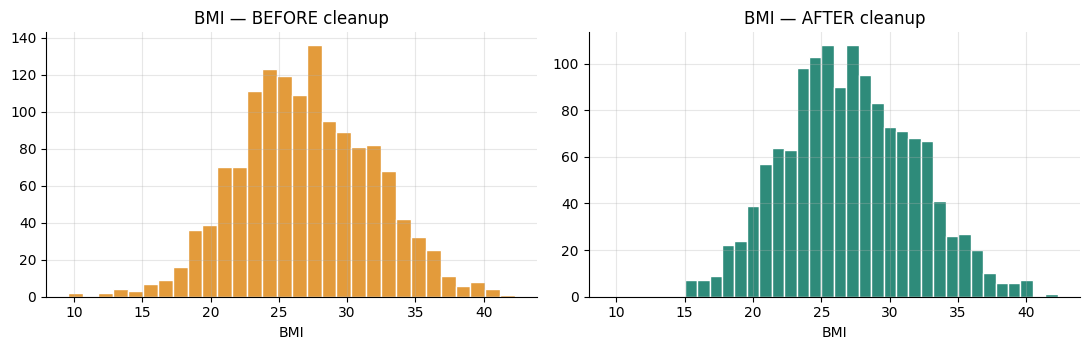

In [10]:
X_train, X_test = X_train.copy(), X_test.copy()

# 5.1 Flag invalid values as NaN (rule-based, done in code)
for d in (X_train, X_test):
    d.loc[d["BMI"] < BMI_MIN, "BMI"] = np.nan

print("NaN count after flagging invalid BMI values")
print(f"  train: {int(X_train.isna().sum().sum())}   test: {int(X_test.isna().sum().sum())}")
bad_idx = X_train.index[X_train["BMI"].isna()]
show_sample(X_train_raw.loc[bad_idx], "BEFORE — rows with implausible BMI (raw values)", n=5)

# 5.2 Fit imputers on TRAIN, apply to both
num_imputer = SimpleImputer(strategy="median").fit(X_train[NUMERIC])
cat_imputer = SimpleImputer(strategy="most_frequent").fit(X_train[["Gender"]])

for d in (X_train, X_test):
    d[NUMERIC]  = num_imputer.transform(d[NUMERIC])
    d[["Gender"]] = cat_imputer.transform(d[["Gender"]])

print(f"\nBMI imputation value (train median): {num_imputer.statistics_[NUMERIC.index('BMI')]:.2f}")
show_sample(X_train.loc[bad_idx], "AFTER — same rows after median imputation", n=5)
print(f"\nRemaining NaNs  train: {int(X_train.isna().sum().sum())}   test: {int(X_test.isna().sum().sum())}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
axes[0].hist(X_train_raw["BMI"], bins=30, color=COLORS["before"], edgecolor="white")
axes[0].set_title("BMI — BEFORE cleanup")
axes[1].hist(X_train["BMI"], bins=30, color=COLORS["after"], edgecolor="white")
axes[1].set_title("BMI — AFTER cleanup")
for a in axes: a.set_xlabel("BMI")
plt.tight_layout(); plt.show()

## 6. Encoding Categorical Data

`Gender` is the only text column → **one-hot encoded** (`drop_first=True` avoids the redundant dummy column). The test set is re-indexed to the training columns so both always have identical features. The remaining lifestyle / history columns are already 0/1.

In [11]:
show_sample(X_train, "BEFORE ENCODING", n=5, cols=["Age", "Gender", "Smoking", "Heart_Disease"])

X_train = pd.get_dummies(X_train, columns=["Gender"], drop_first=True, dtype=int)
X_test  = pd.get_dummies(X_test,  columns=["Gender"], drop_first=True, dtype=int)
X_test  = X_test.reindex(columns=X_train.columns, fill_value=0)   # guarantee same schema

show_sample(X_train, "AFTER ENCODING", n=5, cols=["Age", "Gender_Male", "Smoking", "Heart_Disease"])
print("\nDtypes now:", X_train.dtypes.value_counts().to_dict())


--- BEFORE ENCODING (first 5 rows, shape (1400, 13)) ---


,Age,Gender,Smoking,Heart_Disease
725,22.0,Female,1,0
1651,30.0,Male,1,0
1193,26.0,Male,1,0
994,39.0,Male,1,0
980,22.0,Female,0,0



--- AFTER ENCODING (first 5 rows, shape (1400, 13)) ---


,Age,Gender_Male,Smoking,Heart_Disease
725,22.0,0,1,0
1651,30.0,1,1,0
1193,26.0,1,1,0
994,39.0,1,1,0
980,22.0,0,0,0



Dtypes now: {dtype('int64'): 7, dtype('float64'): 6}
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## 7. Feature Engineering

New features are derived from the cleaned raw values (so this step runs **before** scaling):

| Feature | Definition | Rationale |
|---|---|---|
| `Pulse_Pressure` | systolic − diastolic, clipped at 0 | Arterial stiffness indicator; clipping handles inverted readings |
| `BP_Inverted_Flag` | 1 if diastolic ≥ systolic | Keeps the data-quality signal instead of discarding it |
| `MAP` | diastolic + ⅓·pulse pressure | Mean arterial pressure |
| `BMI_Category` | 0 < 25, 1 = 25–30, 2 ≥ 30 | Clinical weight classes (ordinal) |
| `BP_Risk_Category` | 0 normal · 1 elevated · 2 stage 1 · 3 stage 2 | Simplified ACC/AHA categories (ordinal) |
| `Age_60_Plus` | Age ≥ 60 | Stroke risk rises sharply with age |
| `High_Cholesterol` | Cholesterol > 240 | Clinical threshold |
| `High_Glucose` | Glucose > 140 | Clinical threshold |


--- BEFORE feature engineering (first 4 rows, shape (1400, 13)) ---


,Age,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic
725,22.0,22.4,144.0,107.0
1651,30.0,36.7,167.0,113.0
1193,26.0,25.9,114.0,108.0
994,39.0,36.5,115.0,85.0



--- AFTER feature engineering (new columns) (first 4 rows, shape (1400, 21)) ---


,Pulse_Pressure,BP_Inverted_Flag,MAP,BMI_Category,BP_Risk_Category,Age_60_Plus,High_Cholesterol,High_Glucose
725,37.0,0,119.333333,0,3,0,0,0
1651,54.0,0,131.000000,2,3,0,0,0
1193,6.0,0,110.000000,1,3,0,1,1
994,30.0,0,95.000000,2,2,0,1,1



Feature count: 13 → 21


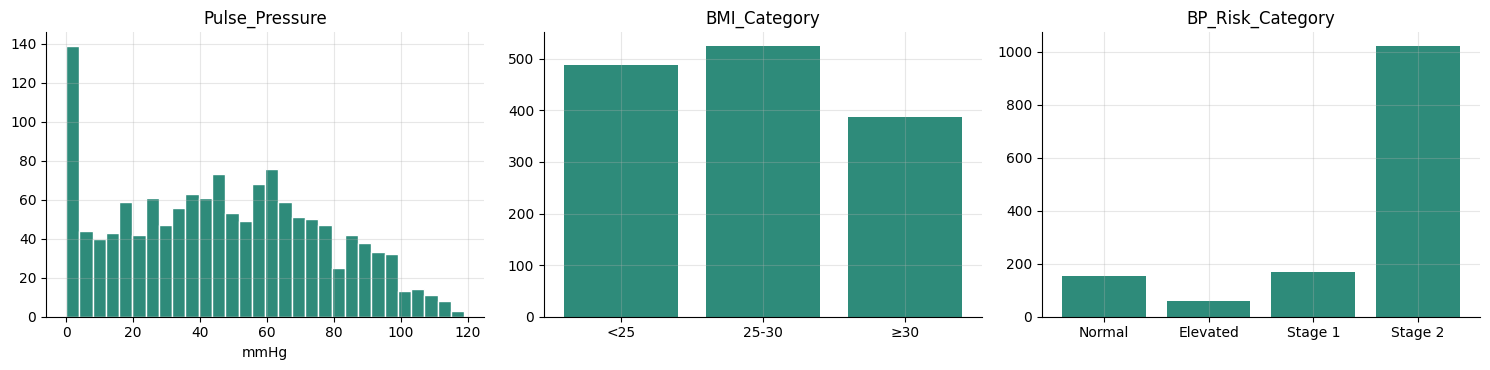

In [12]:
def engineer_features(d):
    d = d.copy()
    sys_, dia = d["Blood_Pressure_Systolic"], d["Blood_Pressure_Diastolic"]
    d["BP_Inverted_Flag"] = (dia >= sys_).astype(int)
    d["Pulse_Pressure"]   = (sys_ - dia).clip(lower=0)
    d["MAP"]              = dia + d["Pulse_Pressure"] / 3
    d["BMI_Category"]     = np.select([d["BMI"] < 25, d["BMI"] < 30], [0, 1], default=2)
    d["BP_Risk_Category"] = np.select(
        [(sys_ < 120) & (dia < 80), (sys_ < 130) & (dia < 80), (sys_ < 140) & (dia < 90)],
        [0, 1, 2], default=3)
    d["Age_60_Plus"]      = (d["Age"] >= 60).astype(int)
    d["High_Cholesterol"] = (d["Cholesterol"] > 240).astype(int)
    d["High_Glucose"]     = (d["Glucose_Level"] > 140).astype(int)
    return d

NEW_FEATURES = ["Pulse_Pressure", "BP_Inverted_Flag", "MAP", "BMI_Category",
                "BP_Risk_Category", "Age_60_Plus", "High_Cholesterol", "High_Glucose"]

X_train_before_fe = X_train.copy()
X_train = engineer_features(X_train)
X_test  = engineer_features(X_test)

show_sample(X_train_before_fe, "BEFORE feature engineering", n=4,
            cols=["Age", "BMI", "Blood_Pressure_Systolic", "Blood_Pressure_Diastolic"])
show_sample(X_train, "AFTER feature engineering (new columns)", n=4, cols=NEW_FEATURES)
print(f"\nFeature count: {X_train_before_fe.shape[1]} → {X_train.shape[1]}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(X_train["Pulse_Pressure"], bins=30, color=COLORS["after"], edgecolor="white")
axes[0].set_title("Pulse_Pressure"); axes[0].set_xlabel("mmHg")
for ax, col, labels in [(axes[1], "BMI_Category", ["<25", "25-30", "≥30"]),
                        (axes[2], "BP_Risk_Category", ["Normal", "Elevated", "Stage 1", "Stage 2"])]:
    vc = X_train[col].value_counts().sort_index()
    ax.bar([labels[i] for i in vc.index], vc.values, color=COLORS["after"])
    ax.set_title(col)
plt.tight_layout(); plt.show()

## 8. Normalization & Scaling

Two different goals, handled separately and **fit on the training set only**:

* **Normalization (distribution shape):** skewed features are made more symmetric with a Yeo-Johnson power transform. It is applied *only* to columns whose |skewness| exceeds 0.75, so already-symmetric features are left alone.
* **Scaling (range):** all continuous features are standardized to mean 0 and standard deviation 1 with `StandardScaler`, so features measured in different units (years, mmHg, mg/dL) are comparable for distance- and gradient-based models.

Binary and ordinal category columns are not scaled.

Skewness (train) — transform threshold |skew| > 0.75


,Age,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol,Glucose_Level,Pulse_Pressure,MAP
skew_before,0.018,0.175,-0.014,0.04,0.008,0.044,0.141,-0.014


Columns needing normalization: none (all roughly symmetric)

--- BEFORE scaling (first 4 rows, shape (1400, 21)) ---


,Age,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol,Glucose_Level,Pulse_Pressure,MAP
725,22.0,22.4,144.0,107.0,211.0,85.0,37.0,119.333333
1651,30.0,36.7,167.0,113.0,211.0,117.0,54.0,131.000000
1193,26.0,25.9,114.0,108.0,275.0,160.0,6.0,110.000000
994,39.0,36.5,115.0,85.0,260.0,154.0,30.0,95.000000



--- AFTER scaling (first 4 rows, shape (1400, 21)) ---


,Age,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol,Glucose_Level,Pulse_Pressure,MAP
725,-1.441075,-0.980687,0.357818,1.052275,-0.303324,-1.301297,-0.318730,1.039871
1651,-1.030648,2.016497,1.239157,1.402686,-0.303324,-0.431825,0.246824,1.858246
1193,-1.235861,-0.247111,-0.791755,1.110677,1.166146,0.736528,-1.350033,0.385171
994,-0.568918,1.974579,-0.753436,-0.232564,0.821739,0.573502,-0.551605,-0.667026



Range / spread summary


,mean_before,std_before,mean_after,std_after
Age,50.089,19.499,-0.0,1.0
BMI,27.079,4.773,-0.0,1.0
Blood_Pressure_Systolic,134.662,26.106,-0.0,1.0
Blood_Pressure_Diastolic,88.982,17.129,-0.0,1.0
Cholesterol,224.211,43.569,-0.0,1.0
Glucose_Level,132.893,36.817,0.0,1.0
Pulse_Pressure,46.581,30.070,-0.0,1.0
MAP,104.509,14.261,0.0,1.0


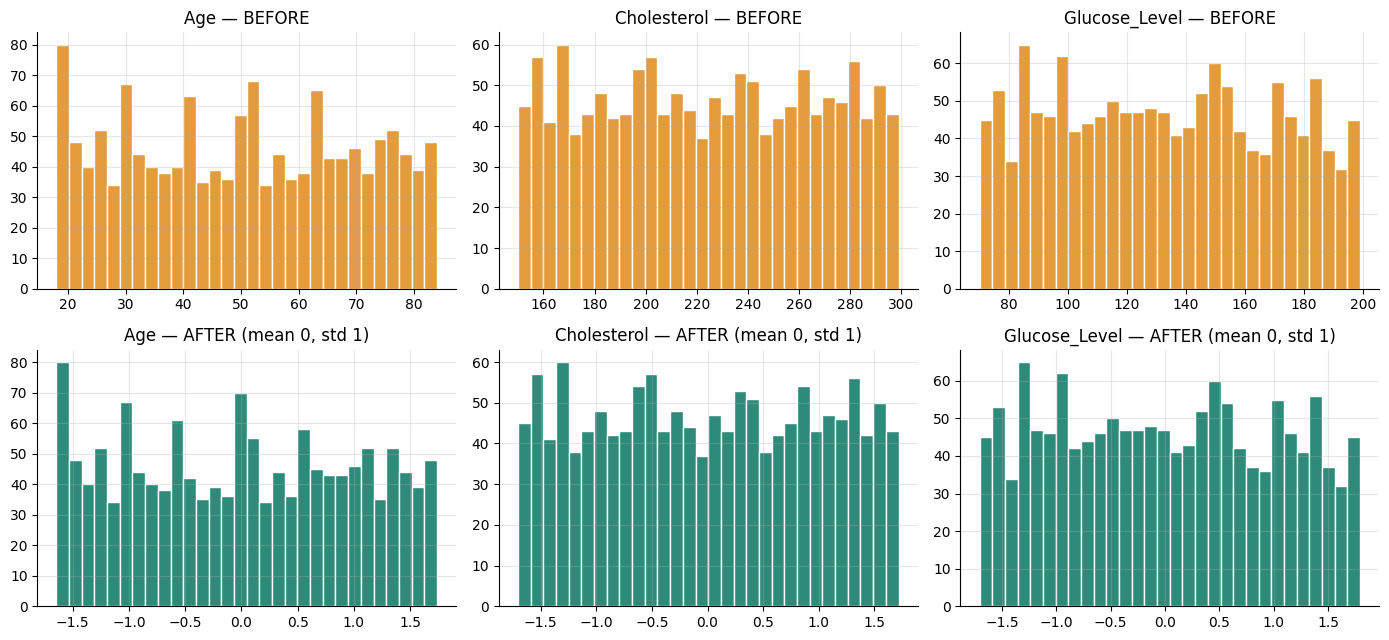

In [13]:
CONTINUOUS = NUMERIC + ["Pulse_Pressure", "MAP"]

skew_before = X_train[CONTINUOUS].skew().rename("skew_before")
SKEW_LIMIT = 0.75
to_transform = skew_before[skew_before.abs() > SKEW_LIMIT].index.tolist()
print(f"Skewness (train) — transform threshold |skew| > {SKEW_LIMIT}")
display(skew_before.round(3).to_frame().T)
print("Columns needing normalization:", to_transform or "none (all roughly symmetric)")

X_train_before_scale = X_train.copy()

# 8.1 Normalization (shape)
if to_transform:
    pt = PowerTransformer(method="yeo-johnson", standardize=False).fit(X_train[to_transform])
    X_train[to_transform] = pt.transform(X_train[to_transform])
    X_test[to_transform]  = pt.transform(X_test[to_transform])

# 8.2 Scaling (range)
scaler = StandardScaler().fit(X_train[CONTINUOUS])
X_train[CONTINUOUS] = scaler.transform(X_train[CONTINUOUS])
X_test[CONTINUOUS]  = scaler.transform(X_test[CONTINUOUS])

show_sample(X_train_before_scale, "BEFORE scaling", n=4, cols=CONTINUOUS)
show_sample(X_train, "AFTER scaling", n=4, cols=CONTINUOUS)

summary = pd.DataFrame({
    "mean_before": X_train_before_scale[CONTINUOUS].mean(), "std_before": X_train_before_scale[CONTINUOUS].std(),
    "mean_after":  X_train[CONTINUOUS].mean(),              "std_after":  X_train[CONTINUOUS].std()}).round(3)
print("\nRange / spread summary"); display(summary)

show = ["Age", "Cholesterol", "Glucose_Level"]
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for j, col in enumerate(show):
    axes[0, j].hist(X_train_before_scale[col], bins=30, color=COLORS["before"], edgecolor="white")
    axes[0, j].set_title(f"{col} — BEFORE")
    axes[1, j].hist(X_train[col], bins=30, color=COLORS["after"], edgecolor="white")
    axes[1, j].set_title(f"{col} — AFTER (mean 0, std 1)")
plt.tight_layout(); plt.show()

## 9. Class Balancing (SMOTE-NC)

Only about 1 in 20 patients has a stroke, so a model that always predicts "no stroke" would look accurate but be useless. We oversample the minority class with **SMOTE-NC** — the variant of SMOTE that handles a mix of continuous and categorical/binary columns, so synthetic rows never contain impossible values like `Smoking = 0.37`.

Balancing is applied to the **training set only**. The test set keeps its natural class ratio so evaluation stays honest.

Before SMOTE-NC: {0: np.int64(1329), 1: np.int64(71)}   →   After: {0: np.int64(1329), 1: np.int64(1329)}
Training shape:  (1400, 21) → (2658, 21)


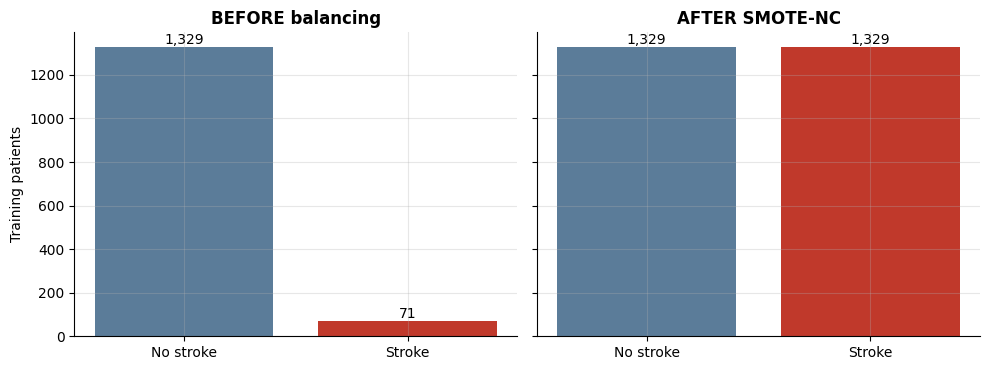


--- Synthetic minority rows created by SMOTE-NC (first 4 rows, shape (1258, 21)) ---


,Age,Blood_Pressure_Systolic,Smoking,Heart_Disease,Age_60_Plus
1400,0.716278,0.822524,1,0,1
1401,1.080298,1.383937,1,0,1
1402,1.180606,1.033437,1,1,1
1403,1.571580,1.003665,1,1,1


In [14]:
cat_idx = [i for i, c in enumerate(X_train.columns) if c not in CONTINUOUS]
smote = SMOTENC(categorical_features=cat_idx, random_state=RANDOM_STATE)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

before, after = y_train.value_counts().sort_index(), y_train_bal.value_counts().sort_index()
print(f"Before SMOTE-NC: {dict(before)}   →   After: {dict(after)}")
print(f"Training shape:  {X_train.shape} → {X_train_bal.shape}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, vc, title in [(axes[0], before, "BEFORE balancing"), (axes[1], after, "AFTER SMOTE-NC")]:
    bars = ax.bar(["No stroke", "Stroke"], vc.values, color=[COLORS["neg"], COLORS["pos"]])
    for b, v in zip(bars, vc.values):
        ax.text(b.get_x() + b.get_width()/2, v, f"{v:,}", ha="center", va="bottom")
    ax.set_title(title, fontweight="bold")
axes[0].set_ylabel("Training patients")
plt.tight_layout(); plt.show()

n_new = len(X_train_bal) - len(X_train)
show_sample(X_train_bal.tail(n_new), "Synthetic minority rows created by SMOTE-NC",
            n=4, cols=["Age", "Blood_Pressure_Systolic", "Smoking", "Heart_Disease", "Age_60_Plus"])

## 10. Baseline Models — Does the Preprocessing Help?

A quick sanity check with two simple models. Because Stroke is rare, **accuracy is misleading**; we report precision, recall, F1 and ROC-AUC for the positive (stroke) class. All models are evaluated on the same untouched test set.

,precision,recall,f1,roc_auc
model,,,,
LogReg — no balancing,0.900,0.871,0.885,0.998
LogReg — SMOTE-NC,0.775,1.000,0.873,0.997
RandForest — no balancing,1.000,1.000,1.000,1.000
RandForest — SMOTE-NC,1.000,0.968,0.984,1.000


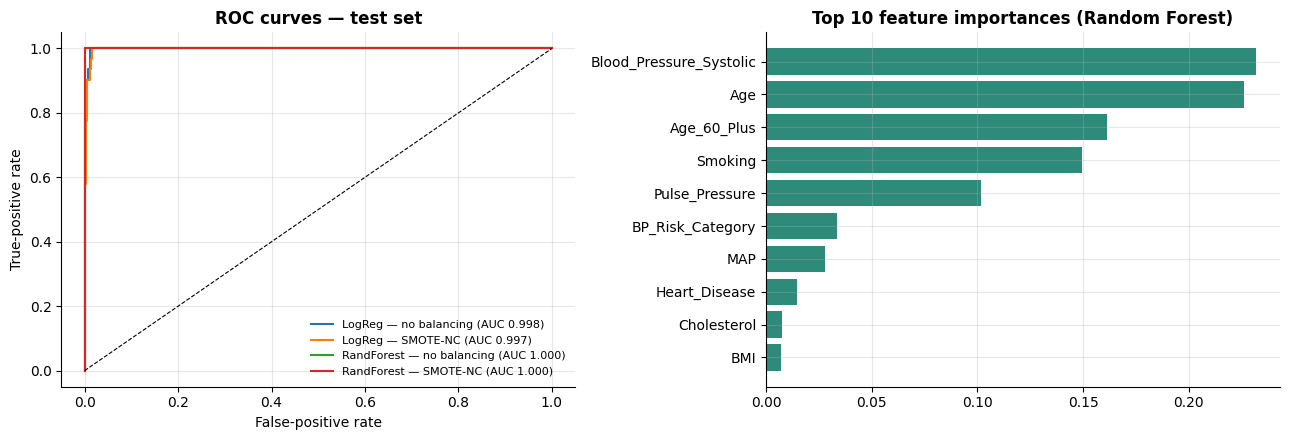

Confusion matrix — Random Forest + SMOTE-NC (rows = actual, cols = predicted)
          pred 0  pred 1
actual 0     569       0
actual 1       1      30


In [15]:
def evaluate(name, model, Xtr, ytr):
    model.fit(Xtr, ytr)
    pred, prob = model.predict(X_test), model.predict_proba(X_test)[:, 1]
    return {"model": name,
            "precision": precision_score(y_test, pred, zero_division=0),
            "recall":    recall_score(y_test, pred),
            "f1":        f1_score(y_test, pred),
            "roc_auc":   roc_auc_score(y_test, prob)}, model, pred, prob

runs = {
    "LogReg — no balancing":   (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), X_train, y_train),
    "LogReg — SMOTE-NC":       (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), X_train_bal, y_train_bal),
    "RandForest — no balancing": (RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1), X_train, y_train),
    "RandForest — SMOTE-NC":   (RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1), X_train_bal, y_train_bal),
}
rows, fitted, probs = [], {}, {}
for name, (m, Xtr, ytr) in runs.items():
    r, fm, pred, prob = evaluate(name, m, Xtr, ytr)
    rows.append(r); fitted[name] = (fm, pred); probs[name] = prob

results = pd.DataFrame(rows).set_index("model").round(3)
display(results)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set_xlabel("False-positive rate"); axes[0].set_ylabel("True-positive rate")
axes[0].set_title("ROC curves — test set", fontweight="bold"); axes[0].legend(frameon=False, fontsize=8)

rf = fitted["RandForest — SMOTE-NC"][0]
imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values().tail(10)
axes[1].barh(imp.index, imp.values, color=COLORS["after"])
axes[1].set_title("Top 10 feature importances (Random Forest)", fontweight="bold")
plt.tight_layout(); plt.show()

best_pred = fitted["RandForest — SMOTE-NC"][1]
print("Confusion matrix — Random Forest + SMOTE-NC (rows = actual, cols = predicted)")
print(pd.DataFrame(confusion_matrix(y_test, best_pred),
                   index=["actual 0", "actual 1"], columns=["pred 0", "pred 1"]))

## 11. Using This Dataset to Solve a Machine-Learning Problem

**Problem statement.** Predict whether a patient will have a stroke from routine clinical measurements and lifestyle factors. This is a **binary classification** task on tabular data, where the cost of a missed stroke (false negative) is much higher than a false alarm — so the goal is a screening tool that ranks patients by risk.

**Approach for the final project**

1. **Features:** the cleaned, encoded, engineered and scaled features produced here (`train_processed.csv` / `test_processed.csv`).
2. **Imbalance:** use the SMOTE-NC training set, and also compare against `class_weight="balanced"` and threshold tuning.
3. **Models to compare:** Logistic Regression (interpretable baseline), Random Forest, Gradient Boosting / XGBoost, and SVM or a small neural network.
4. **Validation:** stratified 5-fold cross-validation on the training set, with resampling performed *inside* each fold (imblearn `Pipeline`) to avoid leakage; final score on the held-out test set.
5. **Metrics:** recall and precision for the stroke class, F1, PR-AUC and ROC-AUC. Accuracy is not used as the headline metric.
6. **Interpretation:** permutation importance / SHAP to check that predictions rely on medically sensible drivers (age, blood pressure, smoking).

**Limitations to state in the report**

* Rows were split once; results on only a few dozen positive test cases are noisy — cross-validation matters.
* SMOTE-NC creates synthetic patients; it should never touch the test set.
* The check below tests whether the data looks synthetic (a single rule reproducing the target).

In [16]:
# Does one simple threshold rule reproduce the target? (Checked on the raw training data)
rule = ((X_train_raw["Age"] > 60) & (X_train_raw["Blood_Pressure_Systolic"] > 150) & (X_train_raw["Smoking"] == 1))
tp = int((rule & (y_train == 1)).sum()); fp = int((rule & (y_train == 0)).sum()); fn = int((~rule & (y_train == 1)).sum())
print("Rule: Age > 60 AND Systolic > 150 AND Smoker")
print(f"  Rule matches {int(rule.sum())} patients  →  true positives {tp}, false positives {fp}, missed strokes {fn}")
print(f"  Precision {tp/max(tp+fp,1):.2f}   Recall {tp/max(tp+fn,1):.2f}")

Rule: Age > 60 AND Systolic > 150 AND Smoker
  Rule matches 71 patients  →  true positives 71, false positives 0, missed strokes 0
  Precision 1.00   Recall 1.00


**Reading the check:** if precision and recall are both close to 1.0, the target was almost certainly generated from a simple rule. In that case tree-based models will score near-perfectly, which reflects how the data was built rather than real-world predictive power — this should be stated as a limitation in the final report.

## 12. Export Processed Data

In [17]:
train_processed = X_train.assign(**{TARGET: y_train.values})
test_processed  = X_test.assign(**{TARGET: y_test.values})
train_balanced  = X_train_bal.assign(**{TARGET: y_train_bal.values})

train_processed.to_csv("train_processed.csv", index=False)
test_processed.to_csv("test_processed.csv", index=False)
train_balanced.to_csv("train_balanced_smotenc.csv", index=False)

print("Saved:")
for f in ("dataset_url.txt", "train_processed.csv", "test_processed.csv", "train_balanced_smotenc.csv"):
    print(f"  ✓ {f}")

steps = pd.DataFrame({
    "Step": ["Drop identifier", "Invalid → NaN → median imputation", "One-hot encoding (Gender)",
             "Feature engineering", "Normalization (Yeo-Johnson, if skewed)", "Scaling (StandardScaler)",
             "Class balancing (SMOTE-NC, train only)"],
    "Shape after": [df.shape, X_train_raw.shape, X_train_before_fe.shape, X_train_before_scale.shape,
                    X_train_before_scale.shape, X_train.shape, X_train_bal.shape]})
print("\nPipeline summary (feature matrix shapes)"); display(steps)

Saved:
  ✓ dataset_url.txt
  ✓ train_processed.csv
  ✓ test_processed.csv
  ✓ train_balanced_smotenc.csv

Pipeline summary (feature matrix shapes)


,Step,Shape after
0,Drop identifier,"(2000, 14)"
1,Invalid → NaN → median imputation,"(1400, 13)"
2,One-hot encoding (Gender),"(1400, 13)"
3,Feature engineering,"(1400, 21)"
4,"Normalization (Yeo-Johnson, if skewed)","(1400, 21)"
5,Scaling (StandardScaler),"(1400, 21)"
6,"Class balancing (SMOTE-NC, train only)","(2658, 21)"
